In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
df= pd.read_csv('../data/cleaned_router_telemetry_dataset.csv')

In [2]:
print(df.shape)
df.head()

(2995, 17)


,vendor,router_model,slot_id,cpu_percent,memory_percent,heap_percent,temperature_c,fan_speed_rpm,power_draw_w,interface_error_count,packet_drop_rate,latency_ms,uptime_hours,alarm_count,card_status,link_status,isolate_required
0,Cisco,CRS-1,slot-6,44.36,43.99,40.66,45.0,6014,620.9,254,6.436,131.31,17622.0,4,ok,up,1
1,Ciena,3924,slot-7,43.39,37.57,38.84,60.1,5388,692.3,250,5.871,120.15,13907.4,4,ok,up,1
2,Cisco,CRS-1,slot-1,66.11,15.89,23.07,46.7,6683,248.7,152,3.145,58.89,31815.3,2,ok,up,0
3,Juniper,MX480,slot-6,47.10,48.46,39.19,41.2,5968,553.7,267,5.402,110.12,7314.8,3,warning,up,1
4,Cisco,ASR9001,slot-2,21.61,41.84,28.17,56.8,7394,398.0,118,3.490,59.66,49896.6,1,ok,up,0


In [3]:
df.describe()

,cpu_percent,memory_percent,heap_percent,temperature_c,fan_speed_rpm,power_draw_w,interface_error_count,packet_drop_rate,latency_ms,uptime_hours,alarm_count,isolate_required
count,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000
mean,37.551950,41.276681,34.373336,50.949850,6565.437396,500.836628,191.979967,4.797832,97.163255,25272.325943,2.902170,0.128214
std,14.131558,13.311876,12.626906,12.197595,892.238918,147.310924,95.869252,2.404856,53.288243,14301.386868,1.836716,0.334383
min,0.000000,1.730000,0.000000,25.000000,3520.000000,54.600000,5.000000,0.131000,3.190000,6.200000,0.000000,0.000000
25%,27.970000,32.245000,25.835000,42.200000,5944.000000,399.850000,119.000000,2.995000,58.675000,12817.950000,2.000000,0.000000
50%,36.760000,40.750000,34.020000,50.000000,6632.000000,491.800000,181.000000,4.477000,89.270000,25846.900000,3.000000,0.000000
75%,46.590000,49.560000,42.765000,58.900000,7248.500000,599.150000,256.000000,6.377000,128.385000,37168.800000,4.000000,0.000000
max,99.820000,99.720000,83.580000,104.800000,8000.000000,1036.300000,515.000000,13.421000,489.890000,49992.100000,15.000000,1.000000


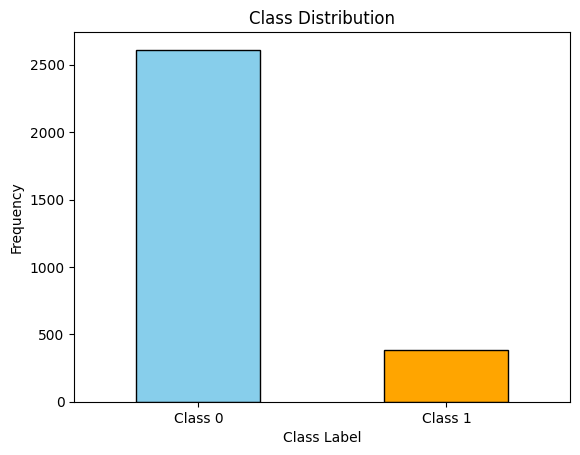

In [4]:






# Count each class
class_counts = df['isolate_required'].value_counts().sort_index()

# Plot bar chart
class_counts.plot(kind='bar', color=['skyblue', 'orange'], edgecolor='black')

plt.title('Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['Class 0', 'Class 1'], rotation=0)
plt.show()

In [5]:
#unique values per categorical column
df[df.select_dtypes(include=['object']).columns].nunique()

vendor           5
router_model    20
slot_id          8
card_status      4
link_status      3
dtype: int64

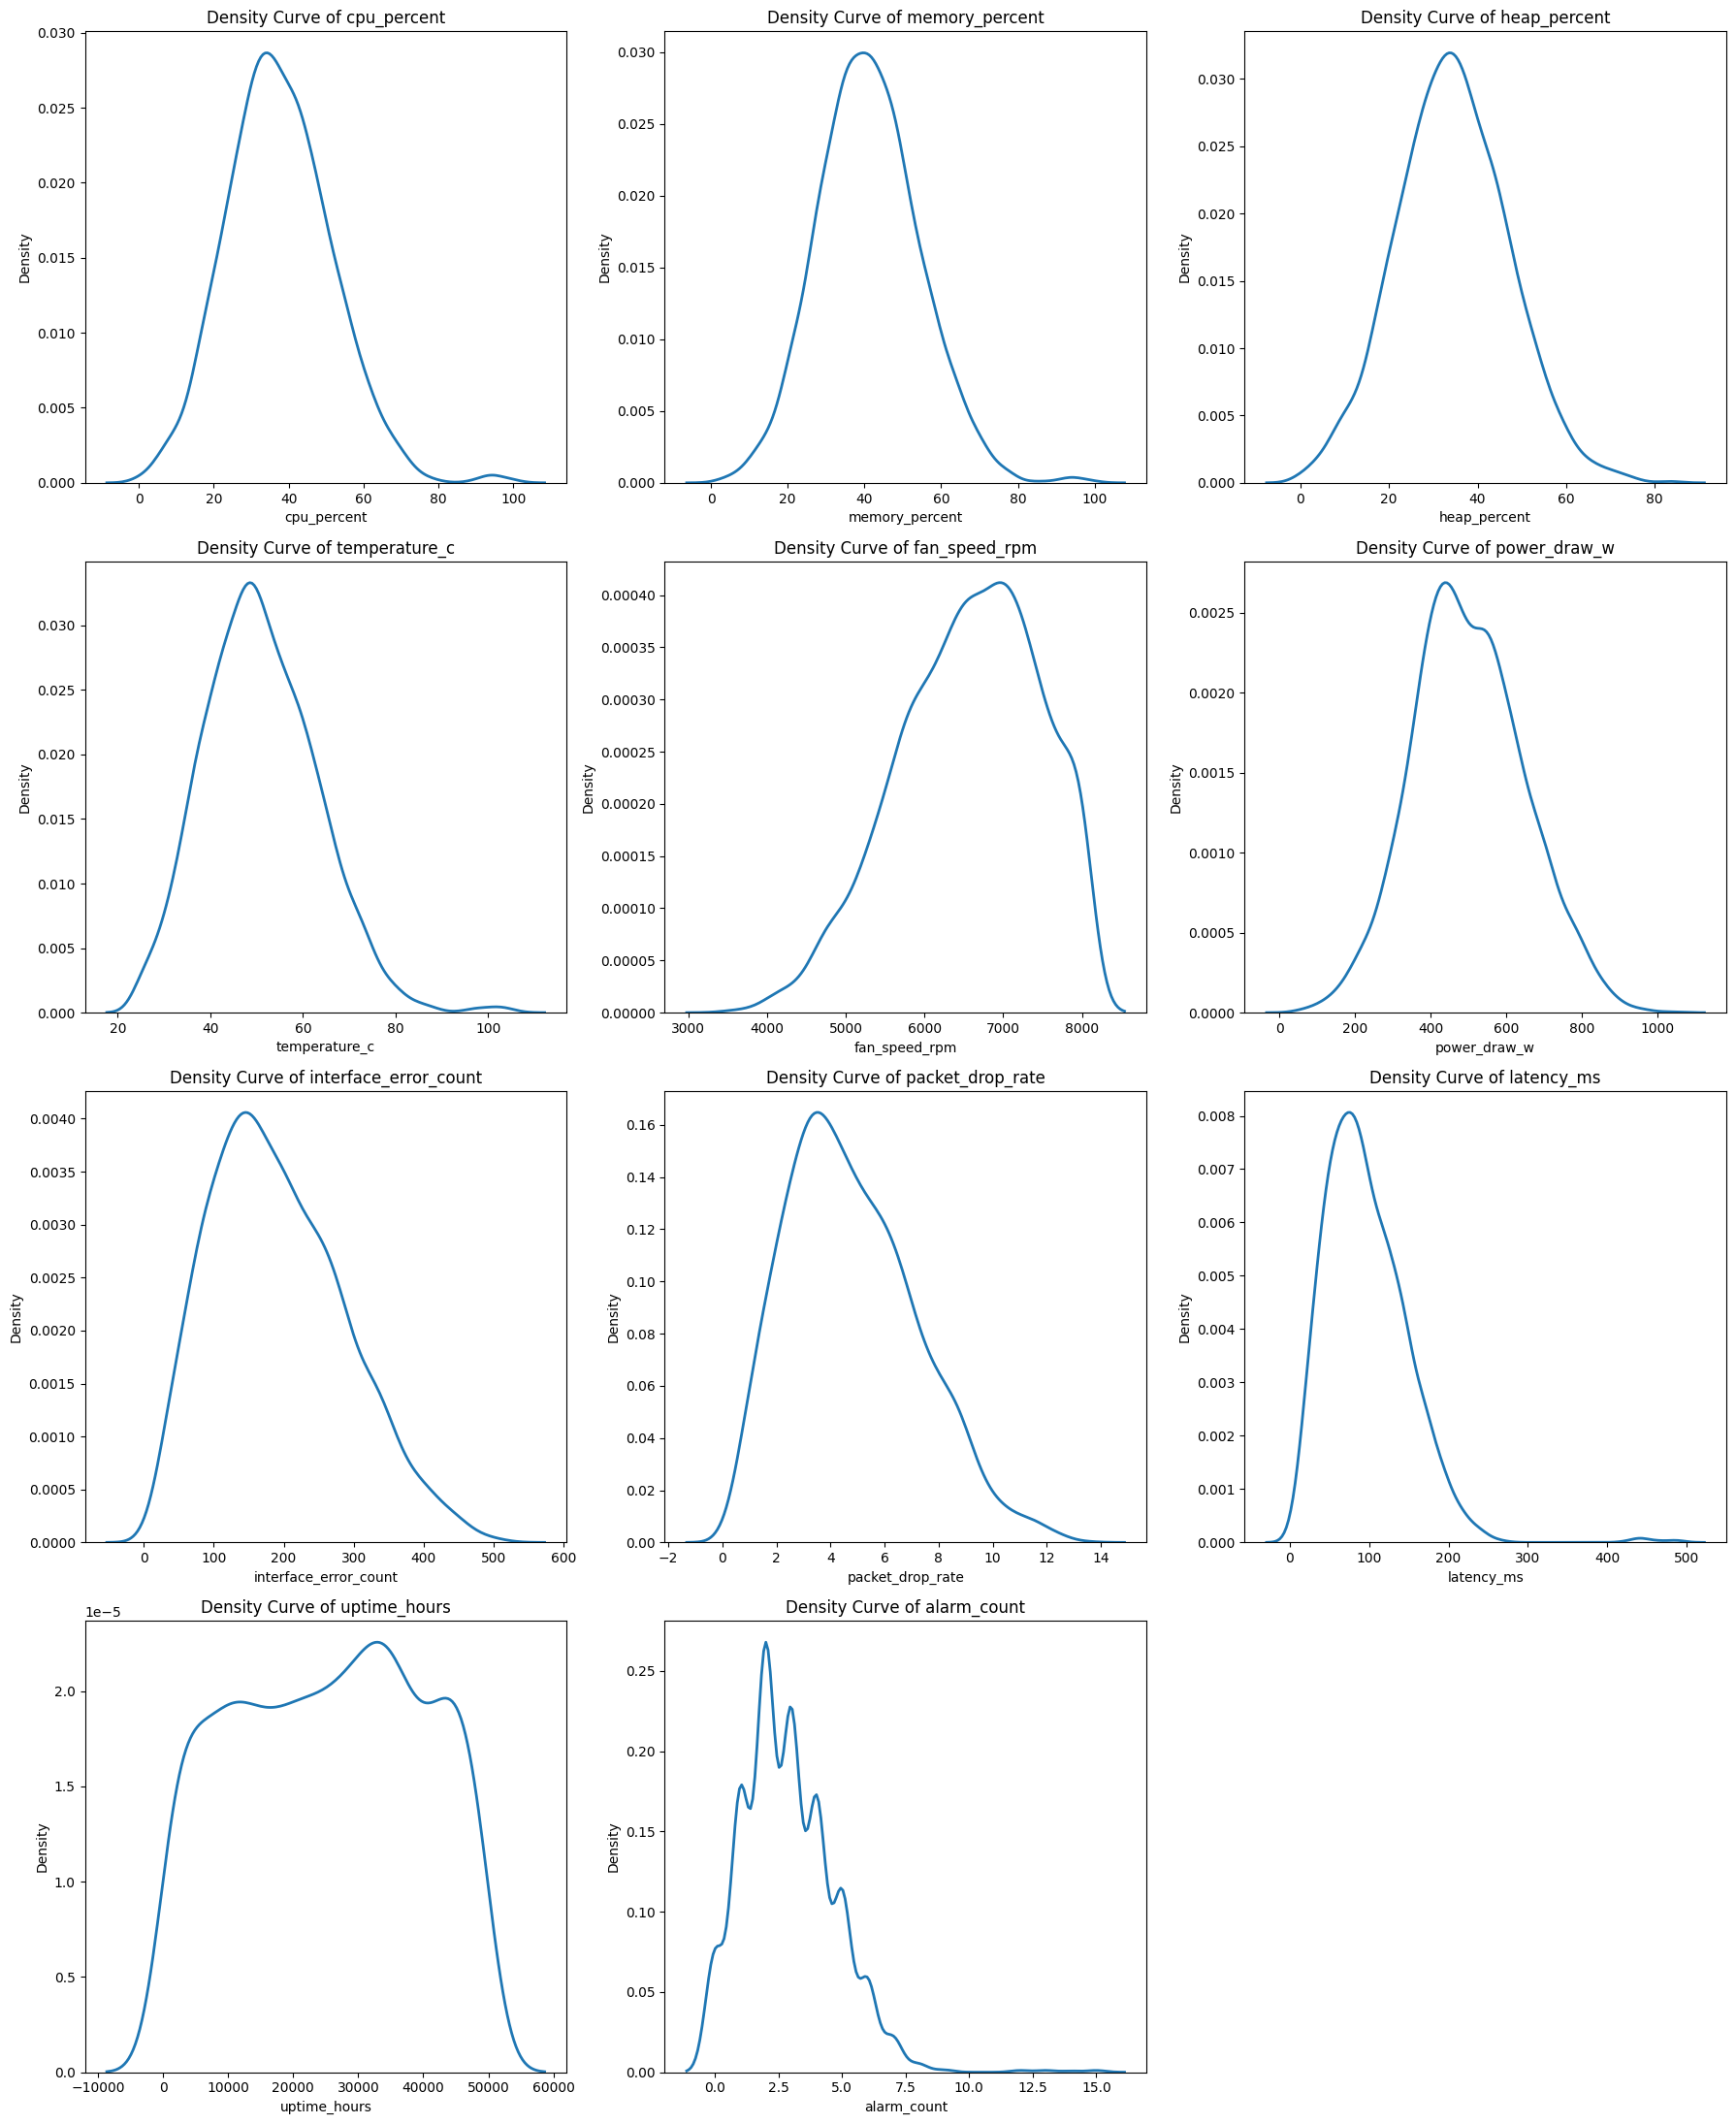

In [6]:
#probability density plots for numeric features to understand skewness and distribution shape
numeric_cols = df.select_dtypes(include=['number']).drop(['isolate_required'], axis=1).columns

plt.figure(figsize=(18, 22))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(4, 3, i)
    sns.kdeplot(data=df, x=col, fill=False, linewidth=2)
    plt.title(f'Density Curve of {col}')
    plt.xlabel(col)
    plt.ylabel('Density')

plt.tight_layout()
plt.show()


In [7]:
#cv ranking for finding the most stable features (approximately)
cv_df = pd.DataFrame({
    'mean': df[numeric_cols].mean().round(2),
    'std': df[numeric_cols].std().round(2),
})

cv_df['cv'] = (cv_df['std'] / cv_df['mean'].replace(0, np.nan)).round(2)
cv_df['cv_percent'] = (cv_df['cv'] * 100).round(2)

cv_ranked = cv_df.sort_values(by='cv', ascending=True)

print(cv_ranked)


                           mean       std    cv  cv_percent
fan_speed_rpm           6565.44    892.24  0.14        14.0
temperature_c             50.95     12.20  0.24        24.0
power_draw_w             500.84    147.31  0.29        29.0
memory_percent            41.28     13.31  0.32        32.0
heap_percent              34.37     12.63  0.37        37.0
cpu_percent               37.55     14.13  0.38        38.0
interface_error_count    191.98     95.87  0.50        50.0
packet_drop_rate           4.80      2.40  0.50        50.0
latency_ms                97.16     53.29  0.55        55.0
uptime_hours           25272.33  14301.39  0.57        57.0
alarm_count                2.90      1.84  0.63        63.0


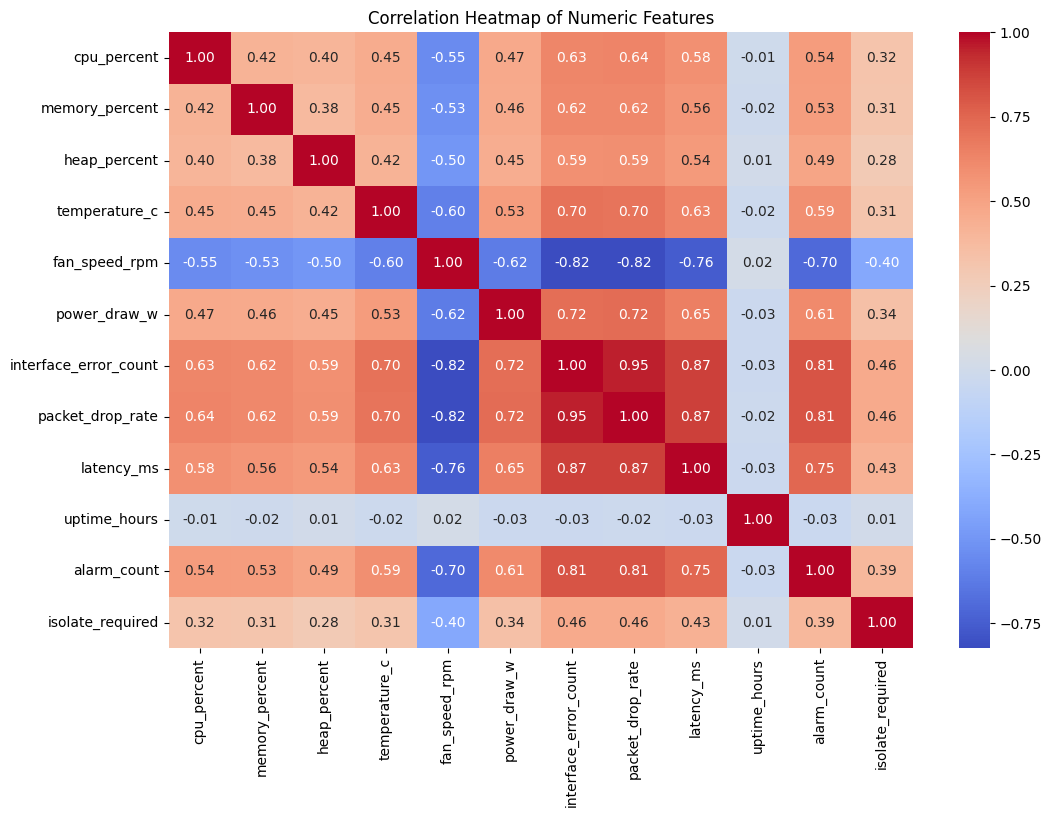

Highly correlated feature pairs (multicollinearity):
               Feature_1              Feature_2  Correlation
2  interface_error_count       packet_drop_rate     0.953487
5       packet_drop_rate             latency_ms     0.873705
3  interface_error_count             latency_ms     0.871978
1          fan_speed_rpm       packet_drop_rate    -0.823942
0          fan_speed_rpm  interface_error_count    -0.818105
6       packet_drop_rate            alarm_count     0.812567
4  interface_error_count            alarm_count     0.811799

 Top 5 Correlated features with target (isolate_required):
packet_drop_rate         0.463573
interface_error_count    0.461306
latency_ms               0.426498
fan_speed_rpm           -0.404568
alarm_count              0.392408
Name: isolate_required, dtype: float64


In [8]:




numeric_cols = df.select_dtypes(include=['number'])

# 3) Correlation matrix
corr_matrix = numeric_cols.corr()

# 4) Full heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

# 5) Set threshold for multicollinearity check
threshold = 0.80   # you can change to 0.80 if you want stricter filtering

# 6) Find highly correlated feature pairs (excluding self-correlation)
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        feature_1 = corr_matrix.columns[i]
        feature_2 = corr_matrix.columns[j]
        corr_value = corr_matrix.iloc[i, j]

        if abs(corr_value) >= threshold:
            high_corr_pairs.append((feature_1, feature_2, corr_value))

# 7) Convert to DataFrame for easy viewing
high_corr_df = pd.DataFrame(high_corr_pairs, columns=["Feature_1", "Feature_2", "Correlation"])

print("Highly correlated feature pairs (multicollinearity):")
print(high_corr_df.sort_values(by="Correlation", key=abs, ascending=False))

# 8) Correlation of all numeric features with target
target_corr = corr_matrix["isolate_required"].sort_values(key=abs, ascending=False)
target_corr.drop("isolate_required", inplace=True)  
print("\n Top 5 Correlated features with target (isolate_required):")
print(target_corr.head())

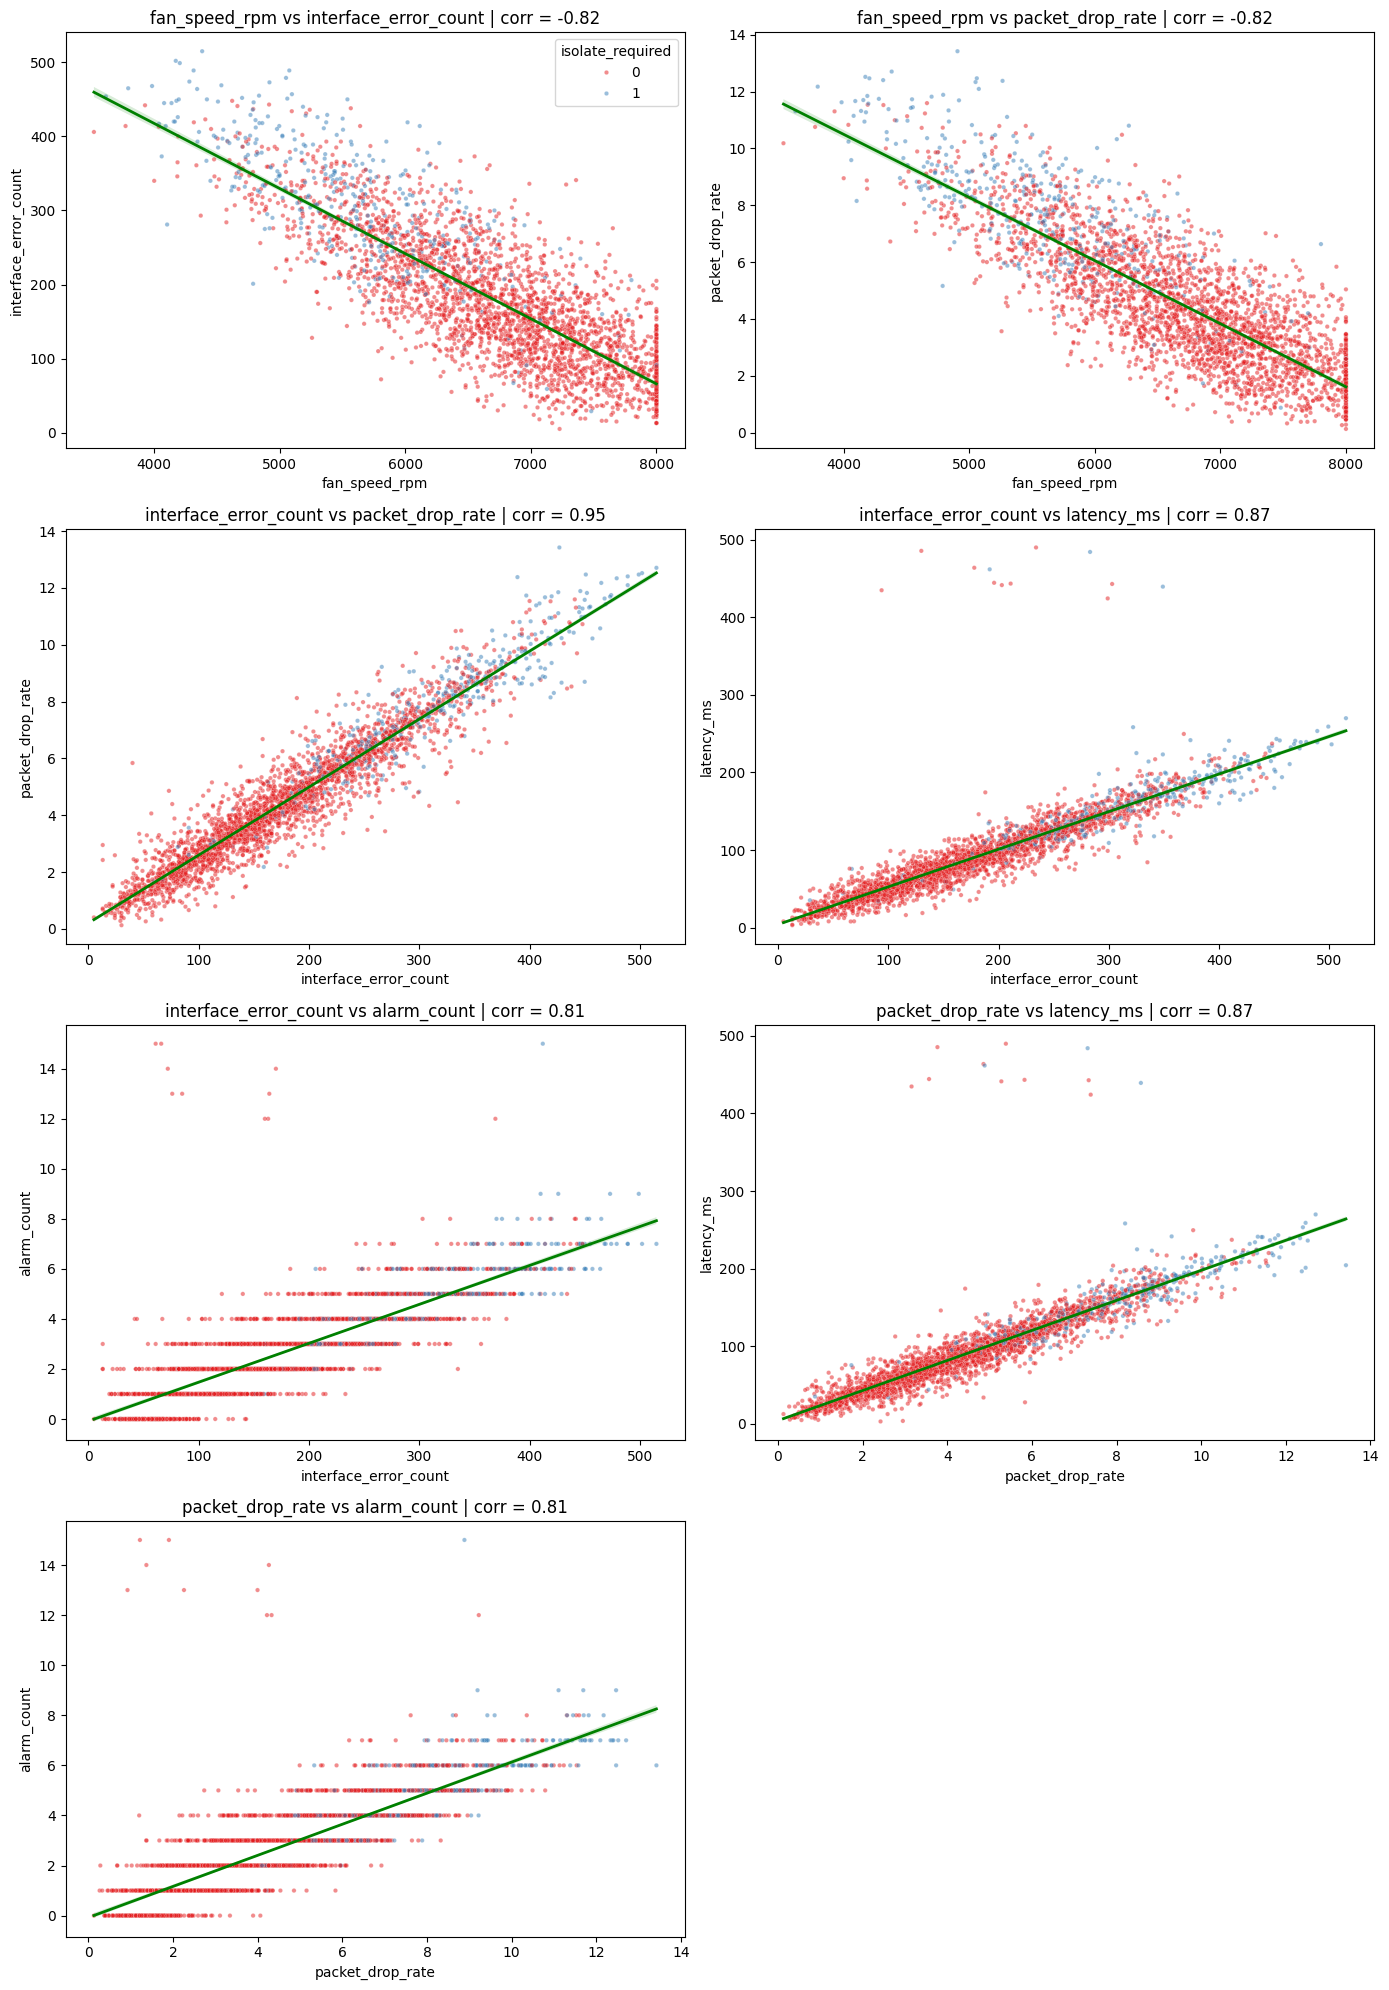

In [9]:
plot_pairs = [(f1, f2, corr_value) for f1, f2, corr_value in high_corr_pairs
              if f1 != "isolate_required" and f2 != "isolate_required"]

n = len(plot_pairs)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 5 * nrows))
axes = axes.flatten()

for i, (f1, f2, corr_value) in enumerate(plot_pairs):
    sns.scatterplot(
        data=df,
        x=f1,
        y=f2,
        hue="isolate_required",
        alpha=0.5,
        palette="Set1",
        s=10,
        ax=axes[i]
    )
    sns.regplot(
    data=df,
    x=f1,
    y=f2,
    scatter=False,
    line_kws={"color": "green", "linewidth": 2},
    ax=axes[i]
)
    axes[i].set_title(f"{f1} vs {f2} | corr = {corr_value:.2f}")

    if i != 0:
        axes[i].get_legend().remove()

for j in range(len(plot_pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()